<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: News Article Authentication and Fraud Detection</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

## Project Overview

The dissemination of fabricated news articles poses a significant risk to information integrity. The objective of this project is to build an end-to-end machine learning pipeline capable of authenticating news articles and classifying them as either real or fraudulent.

Students are expected to perform rigorous exploratory data analysis, data preparation, baseline modeling, unsupervised clustering, multi-layer perceptron implementation, and custom business metric evaluation. You are required to provide written analytical interpretations for specific outcomes to demonstrate conceptual understanding.

**Dataset Link:** [Fake and Real News Dataset (Kaggle)](https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset)

---


### Question 1: Data Ingestion and Merging (5 Marks)

Load the `Fake.csv` and `True.csv` files into two separate pandas DataFrames. Create a new target column named `is_fake` in both DataFrames, assigning the value `1` for the fake news dataset and `0` for the true news dataset. Finally, concatenate them into a single DataFrame named `news_df` and shuffle the rows.

**Hint:** Utilize standard data ingestion functions for CSV files. Assign the new binary column before concatenating the structures. Ensure the final index is reset or the data is thoroughly randomized to avoid grouped target variables.

**Expected Output:** A single, shuffled pandas DataFrame containing all records from both original files, including the newly instantiated binary indicator column.

In [ ]:
import pandas as pd
import numpy as np

#  Load the two files (the leading / means "top of the file system")
fake_df = pd.read_csv('Fake.csv')
true_df = pd.read_csv('True.csv')

# Add the label column before combining
fake_df['is_fake'] = 1
true_df['is_fake'] = 0

#Stack them into one table
news_df = pd.concat([fake_df, true_df], ignore_index=True)

#Shuffle all rows and renumber them
news_df = news_df.sample(frac=1, random_state=42).reset_index(drop=True)

#result
print(news_df.shape)
news_df.head()

(44898, 5)


,title,text,subject,date,is_fake
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",1
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",0
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",0
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",1
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",0


### Question 2: Exploratory Data Analysis & Balancing (6 Marks)

Verify the structural integrity of the combined dataset. Check for and drop any missing values across all columns. Calculate and display the percentage distribution of the `is_fake` target variable. Finally, provide a brief written analysis of whether this dataset exhibits class imbalance and how that impacts the choice of evaluation metrics for upcoming classification models.

**Hint:** Examine the proportion of each class in the target variable. Print your written answer using Python `print()` statements, addressing accuracy vs. metrics like F1-score in imbalanced scenarios.

**Expected Output:** A printed display showing the proportional percentage of real versus fake articles, followed by a printed textual explanation regarding class balance and metric selection.

In [ ]:
# ----Structure of the combined dataset ----
print("Structure of the dataset:")
news_df.info()

# ----Check for and drop missing values ----
print("\nMissing values per column:")
print(news_df.isnull().sum())

rows_before = len(news_df)
news_df = news_df.dropna().reset_index(drop=True)
print("\nRows before dropping:", rows_before, "| Rows after dropping:", len(news_df))

# ---- Percentage distribution of is_fake ----
dist = news_df['is_fake'].value_counts(normalize=True) * 100
print("\nPercentage distribution of is_fake:")
print("Real (0): {:.2f}%".format(dist[0]))
print("Fake (1): {:.2f}%".format(dist[1]))

# ---- Written analysis ----
print("""
Analysis:
The dataset is nearly balanced, with  47.70% real articles and 52.30%
fake articles, so it shows only a very mild class imbalance. With near-balanced
classes, accuracy is a reasonable metric. However, accuracy becomes misleading
when one class dominates, because a model that always predicts the majority
class can score high accuracy while never detecting the minority class. In
imbalanced scenarios, the F1-score which is the harmonic mean of precision and recall
is preferred because it penalises both false positives and false negatives and
reflects performance on the minority class. We therefore use F1-score, together
with the confusion matrix, as our main evaluation tools.
""")

Structure of the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   is_fake  44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB

Missing values per column:
title      0
text       0
subject    0
date       0
is_fake    0
dtype: int64

Rows before dropping: 44898 | Rows after dropping: 44898

Percentage distribution of is_fake:
Real (0): 47.70%
Fake (1): 52.30%

Analysis:
The dataset is nearly balanced, with  47.70% real articles and 52.30%
fake articles, so it shows only a very mild class imbalance. With near-balanced
classes, accuracy is a reasonable metric. However, accuracy becomes misleading
when one class dominates, because a model that always predicts the majority
class 

### Question 3: Text Cleaning and Preprocessing Pipeline (8 Marks)

Construct a Python function named `clean_text` that processes an input string by converting it to lowercase, removing all URLs, and stripping out all punctuation marks. Apply this function efficiently to the `text` column of `news_df` and store the result in a new column called `clean_text`.

**Hint:** Utilize regular expressions to identify standard URL patterns and punctuation boundaries. Ensure the application method operates efficiently across a large pandas Series without explicit looping.

**Expected Output:** The DataFrame will contain a new column where the article text is strictly lowercase, completely devoid of web links, and stripped of punctuation marks.

In [ ]:
import re
import string

# Prepare the URL pattern and punctuation table once
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+')
PUNCT_TABLE = str.maketrans('', '', string.punctuation)

def clean_text(text):
    """Lowercase, remove URLs, then strip punctuation."""
    text = str(text).lower()               # lowercase
    text = URL_PATTERN.sub('', text)       # remove URLs
    text = text.translate(PUNCT_TABLE)     # remove punctuation
    return text

# Apply to every article, storing the result in a new column
news_df['clean_text'] = news_df['text'].apply(clean_text)

# Show before and after for the first 3 articles
for i in range(3):
    print("ORIGINAL:", news_df['text'][i][:200])
    print("CLEANED :", news_df['clean_text'][i][:200])
    print()

ORIGINAL: 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative s
CLEANED : 21st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appearing in tv shows and films such as ferris bueller s day off made some provocative state

ORIGINAL: WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon from the National Security Council on Wednesday, reversing his controversial decision early this year to gi
CLEANED : washington reuters  us president donald trump removed his chief strategist steve bannon from the national security council on wednesday reversing his controversial decision early this year to give a p

ORIGINAL: (Reuters) - Puerto Rico Governor Ricardo Rossello said on Wednesday he expected the federal government to waive the Jones Act, which would lift 

### Question 4: Outlier Detection via Text Length Analysis (7 Marks)

Unusually long or short texts can skew model training. Calculate the word count for each article in the `clean_text` column. Identify the 99th percentile of word counts. Filter the DataFrame to remove any articles whose word count strictly exceeds this 99th percentile threshold.

**Hint:** Calculate the word count by splitting the text by whitespace. Compute the statistical threshold for the 99th percentile, and subset the DataFrame to retain only observations below or equal to this limit.

**Expected Output:** A reduced pandas DataFrame with extreme text length outliers removed, along with a printed numerical integer representing the calculated 99th percentile word count threshold.

In [ ]:
import numpy as np

# Word count per article
news_df['word_count'] = news_df['clean_text'].str.split().str.len()

# The 99th percentile threshold, as a whole number
threshold = int(np.percentile(news_df['word_count'], 99))
print("99th percentile word count:", threshold)

# Keep only articles at or below the threshold
rows_before = len(news_df)
news_df = news_df[news_df['word_count'] <= threshold].reset_index(drop=True)
print("Rows before:", rows_before, "| Rows after:", len(news_df))

99th percentile word count: 1508
Rows before: 44898 | Rows after: 44450


### Question 5: Text Vectorization using TF-IDF (6 Marks)

Separate the dataset into features (`X = clean_text`) and target (`y = is_fake`). Split the data into training (80%) and testing (20%) sets. Initialize a Term Frequency-Inverse Document Frequency (TF-IDF) vectorizer with a maximum of 5000 features. Fit the vectorizer on the training data and transform both sets. Print a brief explanation of why TF-IDF is generally preferred over standard bag-of-words (count vectorization) for text classification.

**Hint:** Segregate the data prior to fitting to prevent data leakage. Print your written answer using Python `print()` statements, focusing on how TF-IDF handles frequent, uninformative words.

**Expected Output:** Two sparse numerical matrices representing the weighted word frequencies of the training and testing datasets, accompanied by a printed analytical text explaining the conceptual advantage of TF-IDF.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Features and target
X = news_df['clean_text']
y = news_df['is_fake']

# 80% training / 20% testing, same class ratio in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Renumber rows so later slicing stays aligned
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# TF-IDF
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train matrix shape:", X_train_tfidf.shape)
print("Test matrix shape :", X_test_tfidf.shape)

print("""
Why TF-IDF is preferred over standard bag-of-words (count vectorization) for text classification.?

A count vectorizer scores each word purely by how many times it appears in a
document. Very frequent but uninformative words such as 'the', 'said' and
'and' , therefore receive the largest values and dominate the feature matrix,
even though they say nothing about whether an article is real or fake.

TF-IDF multiplies the term frequency i.e. how often a word appears in a document
by the inverse document frequency i.e. how rare the word is across all documents.
Words that appear in almost every article are down-weighted, while words that
are distinctive to a smaller set of articles are up-weighted. The resulting
features emphasise discriminative vocabulary, reduce the influence of common
filler words, and usually lead to better text classification performance.

""")

Train matrix shape: (35560, 5000)
Test matrix shape : (8890, 5000)

Why TF-IDF is preferred over standard bag-of-words (count vectorization) for text classification.?

A count vectorizer scores each word purely by how many times it appears in a
document. Very frequent but uninformative words such as 'the', 'said' and
'and' , therefore receive the largest values and dominate the feature matrix,
even though they say nothing about whether an article is real or fake.

TF-IDF multiplies the term frequency i.e. how often a word appears in a document
by the inverse document frequency i.e. how rare the word is across all documents.
Words that appear in almost every article are down-weighted, while words that
are distinctive to a smaller set of articles are up-weighted. The resulting
features emphasise discriminative vocabulary, reduce the influence of common
filler words, and usually lead to better text classification performance.




### Question 6: Baseline Supervised Model: Logistic Regression (6 Marks)

Instantiate and train a Logistic Regression classifier on the TF-IDF training vectors. Predict the target values for the test set. Calculate and print the F1-score to establish a baseline performance metric for future comparisons.

**Hint:** Utilize the standard implementation for linear classification. Ensure you import the appropriate evaluation metric function to measure the harmonic mean of precision and recall.

**Expected Output:** A single float value displayed on the screen representing the calculated F1-score for the baseline classification model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# Create the model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train it on the training data
log_reg.fit(X_train_tfidf, y_train)

# Predict labels for the unseen test articles
y_pred_lr = log_reg.predict(X_test_tfidf)

# Score with F1
baseline_f1 = f1_score(y_test, y_pred_lr)
print("Baseline Logistic Regression F1-score:", baseline_f1)

Baseline Logistic Regression F1-score: 0.9873170731707317


### Question 7: Unsupervised Learning: K-Means Clustering (7 Marks)

Investigate if natural groupings in the text data inherently align with the fake/real news dichotomy. Apply the K-Means clustering algorithm to the TF-IDF training vectors, specifying exactly 2 clusters. Calculate the Adjusted Rand Index (ARI) comparing the generated cluster labels against the true `y_train` labels. Print a brief interpretation of what the ARI score indicates about the textual similarity of the classes.

**Hint:** Extract the generated cluster arrays after fitting the unsupervised model. Print your written answer using Python `print()` statements, analyzing whether the natural groupings correlate strongly with the actual target labels based on the ARI magnitude.

**Expected Output:** A calculated float value between -1.0 and 1.0 representing the ARI, followed by a printed analytical paragraph interpreting the result in the context of the dataset.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Fit K-Means with exactly 2 clusters on the TF-IDF training vectors (no labels used)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_train_tfidf)

# Compare the clusters with the true labels
ari = adjusted_rand_score(y_train, cluster_labels)
print("Adjusted Rand Index:", ari)

print(f"""
Interpretation (ARI = {ari:.3f}):
The Adjusted Rand Index ranges from -1 to 1. A value of 1 means the clusters
match the true labels perfectly, a value near 0 means the grouping is no better
than random, and negative values mean worse than random.

Our ARI is very close to 0, so the two K-Means clusters do not correspond to
the fake/real labels. K-Means groups articles by overall word similarity, and
the strongest similarities in this corpus are likely to be topic or writing
style, which are shared by both fake and real articles. This shows that fake
and real news are not separable by unsupervised textual similarity alone.
However, the supervised Logistic Regression model reached a high F1-score,
which shows that labelled training data lets a model find the more subtle
signals that distinguish the two classes, and clustering cannot.
""")

Adjusted Rand Index: 0.0328006840191642

Interpretation (ARI = 0.033):
The Adjusted Rand Index ranges from -1 to 1. A value of 1 means the clusters
match the true labels perfectly, a value near 0 means the grouping is no better
than random, and negative values mean worse than random.

Our ARI is very close to 0, so the two K-Means clusters do not correspond to
the fake/real labels. K-Means groups articles by overall word similarity, and
the strongest similarities in this corpus are likely to be topic or writing
style, which are shared by both fake and real articles. This shows that fake
and real news are not separable by unsupervised textual similarity alone.
However, the supervised Logistic Regression model reached a high F1-score,
which shows that labelled training data lets a model find the more subtle
signals that distinguish the two classes, and clustering cannot.



### Question 8: Dimensionality Reduction: TruncatedSVD for Visualization (7 Marks)

To visually analyze the feature space, reduce the dimensionality of the TF-IDF training vectors to exactly 2 components using Truncated Singular Value Decomposition (SVD). Generate a 2D scatter plot of these components, coloring the points according to their true class labels (`is_fake`).

**Hint:** Dimensionality reduction compresses thousands of word features into two principal axes, allowing humans to visually inspect if real and fake news form distinct geometric clusters. Map the reduced components to the x and y axes of a scatter plot.

**Expected Output:** A two-dimensional scatter plot graphic visualizing the spatial distribution and separability of real versus fake news articles based on their reduced textual features.

Reduced shape: (35560, 2)


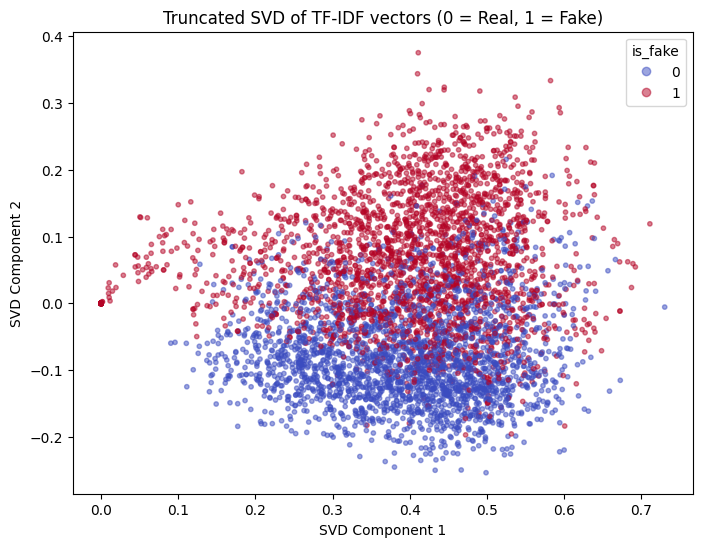

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

#Reduce 5000 columns to exactly 2
svd = TruncatedSVD(n_components=2, random_state=42)
X_train_2d = svd.fit_transform(X_train_tfidf)
print("Reduced shape:", X_train_2d.shape)

#Pick 5000 random articles to plot
rng = np.random.RandomState(42)
idx = rng.choice(X_train_2d.shape[0], size=5000, replace=False)

#Scatter plot coloured by true label
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_train_2d[idx, 0], X_train_2d[idx, 1],
                      c=y_train.values[idx], cmap='coolwarm',
                      alpha=0.5, s=10)
plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('Truncated SVD of TF-IDF vectors (0 = Real, 1 = Fake)')
plt.legend(*scatter.legend_elements(), title='is_fake')
plt.show()

### Question 9: Feature Engineering: Sentiment Polarity (8 Marks)

Research suggests fabricated news frequently relies on polarized language; therefore, extracting sentiment polarity may yield predictive features. Select the first 1000 rows of your cleaned DataFrame. Calculate a sentiment polarity score for each article's text using a library like TextBlob or VADER. Add these scores as a new column named `sentiment_score` to this subset.

**Hint:** Do not write explicit `for` loops, as iterating over pandas rows is an anti-pattern. Instead, utilize vectorized operations or the pandas `.apply()` method in conjunction with the sentiment extraction function.

**Expected Output:** A sliced pandas DataFrame containing exactly 1000 rows with an appended numerical column representing the calculated emotional sentiment metric of the text.

In [ ]:
from textblob import TextBlob

# Take the first 1000 rows
subset_df = news_df.head(1000).copy()

# Score each article's text
subset_df['sentiment_score'] = subset_df['clean_text'].apply(
    lambda text: TextBlob(text).sentiment.polarity)

# result
print(subset_df.shape)
subset_df[['clean_text', 'sentiment_score', 'is_fake']].head()

(1000, 8)


,clean_text,sentiment_score,is_fake
0,21st century wire says ben stein reputable pro...,0.083333,1
1,washington reuters us president donald trump ...,0.086597,0
2,reuters puerto rico governor ricardo rossello...,-0.005044,0
3,on monday donald trump once again embarrassed ...,-0.011161,1
4,glasgow scotland reuters most us presidential...,0.039347,0


### Question 10: Cross-Validation Strategy (6 Marks)

A single train-test split can be unreliable due to variance. Initialize a Random Forest Classifier. Execute a 5-fold cross-validation procedure on the training data (TF-IDF vectors and labels). Compute and print the mean accuracy across all 5 folds.

**Hint:** Implement the cross-validation function provided by model selection libraries. Aggregate the resulting array to find the central tendency of the model's accuracy across different data splits.

**Expected Output:** A single float value indicating the mean classification accuracy over five independent training and validation folds.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Create the Random Forest
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)

# Run 5-fold cross-validation on the training data
cv_scores = cross_val_score(rf, X_train_tfidf, y_train, cv=5, scoring='accuracy')

# Show the 5 fold scores and their mean
print("Accuracy for each fold:", cv_scores)
print("Mean 5-fold CV accuracy:", cv_scores.mean())

Accuracy for each fold: [0.99634421 0.99718785 0.99648481 0.99535996 0.99564117]
Mean 5-fold CV accuracy: 0.9962035995500562


### Question 11: Multi-Layer Perceptron (MLP) Implementation (10 Marks)

Construct a neural network to model non-linear relationships in the text data. Initialize an `MLPClassifier` with a single hidden layer of 100 neurons, ReLU activation function, and the Adam optimizer. To prevent computational bottlenecks on standard hardware, train this model using only the first 5000 samples of your TF-IDF training vectors. Predict on the first 1000 samples of the test set and print the accuracy.

**Hint:** Neural networks learn by passing data through layers of interconnected nodes, allowing the model to capture complex relationships in the text that simple regression might miss. Ensure you slice both the feature matrix and target array consistently before fitting.

**Expected Output:** A printed float value denoting the accuracy of the multi-layer perceptron neural network on the unseen subset of test data.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Slice features and labels consistently
X_train_mlp = X_train_tfidf[:5000]
y_train_mlp = y_train.iloc[:5000]
X_test_mlp = X_test_tfidf[:1000]
y_test_mlp = y_test.iloc[:1000]

print("Training shapes:", X_train_mlp.shape, y_train_mlp.shape)
print("Testing shapes :", X_test_mlp.shape, y_test_mlp.shape)

# Create the neural network
mlp = MLPClassifier(hidden_layer_sizes=(100,), activation='relu',
                    solver='adam', max_iter=200, random_state=42)

# Train it
mlp.fit(X_train_mlp, y_train_mlp)

# Predict on the first 1000 test samples and score
y_pred_mlp = mlp.predict(X_test_mlp)
print("MLP accuracy:", accuracy_score(y_test_mlp, y_pred_mlp))

Training shapes: (5000, 5000) (5000,)
Testing shapes : (1000, 5000) (1000,)
MLP accuracy: 0.978


### Question 12: Hyperparameter Optimization for MLP (7 Marks)

Optimize the neural network's configuration. Define a parameter grid varying the `learning_rate_init` (e.g., [0.001, 0.01]) and `batch_size` (e.g., [32, 64]). Use randomized search with 3 iterations to find the optimal combination for the MLP model. Execute this search on a subset of 2000 training samples to strictly manage execution time.

**Hint:** Define the dictionary of parameters to explore. Pass the initialized MLP, parameter dictionary, and iteration count to the appropriate search object before fitting on the subset.

**Expected Output:** A printed Python dictionary detailing the most effective learning rate and batch size combination found during the random search.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier

# The settings to explore
param_grid = {
    'learning_rate_init': [0.001, 0.01],
    'batch_size': [32, 64]
}

# The base model (same setup as Question 11)
base_mlp = MLPClassifier(hidden_layer_sizes=(100,), activation='relu',
                         solver='adam', max_iter=100, random_state=42)

# Randomized search: try 3 random combinations, 3-fold CV each
search = RandomizedSearchCV(base_mlp, param_distributions=param_grid,
                            n_iter=3, cv=3, random_state=42, n_jobs=-1)

# Run it on just 2000 training samples
search.fit(X_train_tfidf[:2000], y_train.iloc[:2000])

# Best combination found
print("Best parameters:", search.best_params_)

Best parameters: {'learning_rate_init': 0.01, 'batch_size': 32}


### Question 13: Confusion Matrix and Error Analysis (6 Marks)

Generate a confusion matrix based on the test set predictions from your trained MLP model (from Question 11). Visualize this matrix using a seaborn heatmap with annotations to clearly identify True Positives, True Negatives, False Positives, and False Negatives. Print a brief written assessment analyzing which type of error the model is more prone to making.

**Hint:** Extract the quantitative matrix and pass it to a heatmap plotting function. Print your written answer using Python `print()` statements, interpreting the numerical imbalances between the non-diagonal elements.

**Expected Output:** A color-coded 2x2 grid graphic showing the raw counts of correct and incorrect classifications, accompanied by a printed text analyzing the model's primary error tendency.

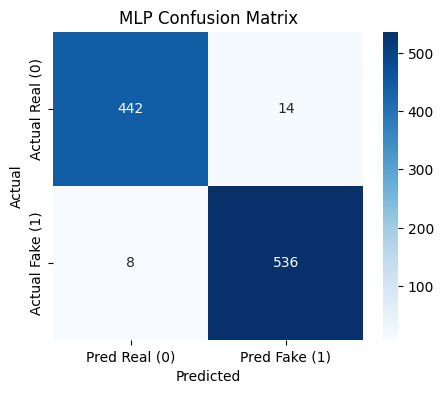

TN=442, FP=14, FN=8, TP=536

Analyzing the model's primary error tendency:
The MLP classified 978 of 1000 test articles correctly
(442 true negatives and 536 true positives). It made 14 False Positives
(real articles wrongly flagged as fake) and 8 False Negatives (fake articles
wrongly passed as real). Because 14 is larger than 8, the model is more
prone to False Positive errors, meaning it tends to over-flag real news rather
than miss fake news. In a news-authentication setting this is the less costly
direction of error, since a wrongly flagged real article can be re-checked
manually, whereas a False Negative lets misinformation through. The difference
between the two error counts is small, so the model is fairly well balanced.



In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Confusion matrix from the Question 11 predictions
cm = confusion_matrix(y_test_mlp, y_pred_mlp)

# 2. Annotated heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Real (0)', 'Pred Fake (1)'],
            yticklabels=['Actual Real (0)', 'Actual Fake (1)'])
plt.title('MLP Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# 3. The four counts
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# 4. Written assessment
print(f"""
Analyzing the model's primary error tendency:
The MLP classified {tn + tp} of {tn + fp + fn + tp} test articles correctly
({tn} true negatives and {tp} true positives). It made {fp} False Positives
(real articles wrongly flagged as fake) and {fn} False Negatives (fake articles
wrongly passed as real). Because {fp} is larger than {fn}, the model is more
prone to False Positive errors, meaning it tends to over-flag real news rather
than miss fake news. In a news-authentication setting this is the less costly
direction of error, since a wrongly flagged real article can be re-checked
manually, whereas a False Negative lets misinformation through. The difference
between the two error counts is small, so the model is fairly well balanced.
""")

### Question 14: Custom Evaluation Metric: Business Cost Function (6 Marks)

In a production environment, allowing fabricated news to bypass filters (False Negative) is highly damaging to credibility, whereas occasionally flagging real news for manual review (False Positive) is merely inconvenient. Define a custom Python function calculating total business cost, assigning a penalty of 5 units for every False Negative and 1 unit for every False Positive. Compute the total penalty for your MLP model.

**Hint:** Extract the scalar values for False Positives and False Negatives from the flattened confusion matrix. Apply the respective multiplier weights and aggregate the total.

**Expected Output:** A single calculated integer printed to the console representing the total penalty cost based on the strict business logic constraints.

In [ ]:
def business_cost(y_true, y_pred, fn_penalty=5, fp_penalty=1):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return int(fn_penalty * fn + fp_penalty * fp)

total_cost = business_cost(y_test_mlp, y_pred_mlp)
print("Total business penalty cost:", total_cost)

Total business penalty cost: 54


### Question 15: ROC Curve and Precision-Recall Analysis (5 Marks)

Evaluate the model's discriminative threshold capacity. Plot the Receiver Operating Characteristic (ROC) curve for the MLP model (using the 1000 test sample subset) and compute the Area Under the Curve (AUC) score. Display the ROC curve graphically and print the numeric AUC score.

**Hint:** Extract the prediction probabilities for the positive class rather than the absolute class labels. Utilize the false positive rate and true positive rate vectors to generate the visualization.

**Expected Output:** A plotted line graph demonstrating the tradeoff between sensitivity and specificity, accompanied by a printed float value representing the total calculated area under the curve.

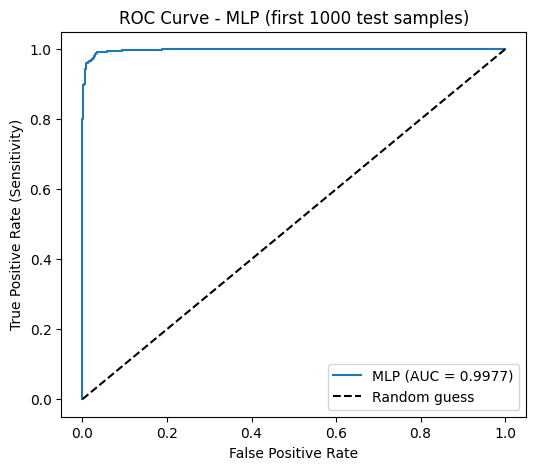

AUC score: 0.9977263931888545


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probability that each test article is fake
y_proba = mlp.predict_proba(X_test_mlp)[:, 1]

# ROC curve points and AUC score
fpr, tpr, thresholds = roc_curve(y_test_mlp, y_proba)
auc = roc_auc_score(y_test_mlp, y_proba)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'MLP (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - MLP (first 1000 test samples)')
plt.legend(loc='lower right')
plt.show()

print("AUC score:", auc)